# Does chromatin shape separate mitoses from the rest of the deep pool? `mo_pad61`, 49 ROIs x 6 clicks

**Why.** `deep_pool_mo_pad61_49roi_6seed.ipynb` showed where mitoses sit in `mo_pad61`'s `tm_score` list. The five
"stuck" ROIs (`211`, `242`, `462`, `524`, `546`) hold 2.2 / 4.2 / 7.1 mitoses in the top 30 / 100 / 300. The other
44 hold 13.7 / 27.1 / 39.3. That notebook only estimated what a shape score could do, from a model. This notebook
measures it directly: on the stuck five, where the question began, and on the other 44, where the list holds more
mitoses and a re-rank has more room.

**History.** The first run covered only the stuck five. The user then asked for all 49 ROIs. The features, masks and
arms below did not change between the two runs; the stuck five's numbers must reproduce the first run's.

**Design.**
- **Candidates.** For each of the 294 clicks (49 ROIs x 6), the top N at `tm_score` of `mo_pad61`'s uncapped list,
  read from the saved `top1000` CSV. N = 300 is the headline; N = 30 and 100 are also reported. No search is re-run.
- **Segmentation.** `refine_template_box`, the adopted multi-Otsu method, copied verbatim, is run at each
  candidate's centre exactly as it runs at a click. A tripwire first re-runs it on all 294 clicks and must reproduce
  the recorded box (`bs`, `tcx`, `tcy`).
- **Mask.**
  - The primary mask is the method's own `selection_mask`: the selected pieces of the dilated top class, which is
    what a production shape score would get.
  - The undilated top-class pixels inside those pieces are a pre-declared sensitivity check. The 1 px dilation
    fills exactly the small concavities that lower solidity and raise roughness.
- **Refusals.** A candidate the method refuses has no shape, for example within 36 px of the ROI edge or with no
  piece near its centre. It is dropped from **every** arm, the `tm_score` baseline included, so shape is never
  credited for acting as an edge filter. Refusals are counted by match bucket, and the unfiltered `tm_score`
  baseline is shown beside the filtered one.
- **Features**, each with the direction declared as mitosis-like:
  - **solidity** (area / convex-hull area), lower = mitosis-like: the **primary** feature;
  - **eccentricity** of the fitted ellipse, higher = mitosis-like: descriptive;
  - **roughness** (perimeter / convex-hull perimeter), higher = mitosis-like: descriptive;
  - **area** in um^2: descriptive, reported as P(mitosis larger);
  - **od** (`chromatin_od`, saved with the list), higher = mitosis-like: a non-shape reference.
- **Separation.** One AUC per ROI and feature: the chance that a mitosis in the top N is more mitosis-like than a
  non-mitosis in the top N. Every (click, detection) pair of the ROI's 6 lists is pooled, and ties count one half.
  The same mitoses recur across a ROI's clicks, so the count of distinct mitoses behind each AUC is reported too.
- **Re-rank.** Inside each click's filtered top N, three arms, then each re-sorted list is re-matched to ground
  truth with `ev.bucket_detections`, the clicked mitosis excluded:
  - `tm_score` as is;
  - **solidity alone**, ascending, ties kept in `tm_score` order;
  - **solidity + tm_score**, the mean of the two within-list ranks, ties kept in `tm_score` order.

  Each arm's TP@10 sits beside the equal-variance prediction from the ROI's own solidity AUC.
- **Summaries.**
  - Every number is averaged first over a ROI's 6 clicks, then over the ROIs of a group (stuck five, other 44).
  - Differences from `tm_score` carry a 95% bootstrap interval over ROIs (10,000 resamples). This is descriptive, not
    a test.
- **Label caveat.** "No label" may include unannotated mitoses, and the visual check of the stuck five is still open.

**Outputs.** `results/shape_mo_pad61_deep_pool_49roi_{features,auc,rerank,refusals}.csv`. Figures are inline only.

In [1]:
import hashlib
import os
import sys
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm, rankdata
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops

sys.path.insert(0, '../..')
from midog_utils import channels as ch
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import production as prod
from midog_utils import seed_selection as ss
from midog_utils import template_match as tm

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)

NB_T0 = time.time()
assert (tm.BASE_SIZE, tm.PATCH_SIZE) == (51, 73) and prod.CHANNEL == 'hematoxylin_od', 'the sizes and channel the verbatim method assumes'

# refine_template_box's constants, copied verbatim from cell 1 of multiotsu_template_refinement_14roi.ipynb
WINDOW = tm.BASE_SIZE                                            # 51 px window around the click
CLASSES = 3                                                      # multi-Otsu classes; the top one is kept
DILATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))  # 3x3 cross
DILATE_ITERATIONS = 1                                            # 1 px
MIN_PIECE_UM2 = 1.0                                              # speck floor
MIN_BASE_UM = 5.0                                                # base case: the click's piece bbox, longer side
CLICK_RADIUS_UM = 3.75                                           # fallback: piece centre within this of the click
MIN_AREA_UM2 = 3.0                                               # selection must cover at least this
MAX_AREA_FRAC = 0.85                                             # ... and at most this fraction of the window
PAD_UM = 0.5                                                     # margin kept around the selection on every side

ARM = 'mo_pad61'
STUCK = ('211.tiff', '242.tiff', '462.tiff', '524.tiff', '546.tiff')
GROUPS = ('stuck 5', 'other 44')
DEPTHS = (30, 100, 300)
HEAD_DEPTH = 300
TOP_K = 10
# pre-declared features: column -> +1 when a larger value is more mitosis-like, -1 when a smaller one is
FEATURES = {'solidity': -1, 'eccentricity': +1, 'roughness': +1, 'area_um2': +1, 'od': +1}
PRIMARY = 'solidity'
MASKS = ('dil', 'raw')                 # dil = the method's selection_mask (primary); raw = undilated top class inside it (sensitivity)
RERANK_ARMS = ('tm_score', 'solidity', 'solidity + tm_score')
N_BOOT = 10_000
BOOT_SEED = 20260930

SMOKE_ROIS = [s for s in os.environ.get('SHAPE_SMOKE_ROIS', '').split(',') if s] or None
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
DEEP = '../../results/deep_pool_mo_pad61_49roi_6seed_postD11'
MO_SRC = '../../results/precision_at_k_49roi_6seed_mopad_postD11'
FG_SRC = '../../results/precision_at_k_49roi_6seed_fillgeom_postD11'
DB_PATH = '../../databases/MIDOG++.json'
SUBSET_DIRS = {'original_14': '../../images/extra_valid', 'testing_35': '../../images/extra_valid/testing_set'}
OUT = {name: f'../../results/shape_mo_pad61_deep_pool_49roi{SUFFIX}_{name}.csv' for name in ('features', 'auc', 'rerank', 'refusals')}
SURFACE, INK, SECONDARY, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
STUCK_C = '#2a78d6'


def group_of(file_name):
    """
        The ROI's group: one of the five stuck ROIs, or one of the other 44.

        file_name (str): the ROI.

        Returns str: 'stuck 5' or 'other 44'.
    """
    return GROUPS[0] if file_name in STUCK else GROUPS[1]


print(f'depths {DEPTHS} (headline {HEAD_DEPTH}); primary {PRIMARY} on the {MASKS[0]} mask; smoke ROIs = {SMOKE_ROIS}')
print('outputs:', *OUT.values(), sep='\n  ')

depths (30, 100, 300) (headline 300); primary solidity on the dil mask; smoke ROIs = None
outputs:
  ../../results/shape_mo_pad61_deep_pool_49roi_features.csv
  ../../results/shape_mo_pad61_deep_pool_49roi_auc.csv
  ../../results/shape_mo_pad61_deep_pool_49roi_rerank.csv
  ../../results/shape_mo_pad61_deep_pool_49roi_refusals.csv


In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this notebook read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


for p in (f'{DEEP}_top1000.csv', f'{DEEP}_per_run.csv', f'{MO_SRC}_templates.csv', f'{MO_SRC}_per_run.csv', f'{FG_SRC}_clicks.csv', DB_PATH):
    print(f'  {sha256_12(p)}  {p}')

DEEP_RUN = pd.read_csv(f'{DEEP}_per_run.csv')
ROIS = tuple(pd.unique(DEEP_RUN['file_name']))
assert len(ROIS) == 49 and set(STUCK) <= set(ROIS)
if SMOKE_ROIS is not None:
    ROIS = tuple(f for f in ROIS if f in SMOKE_ROIS)
DEEP_RUN = DEEP_RUN.set_index(['file_name', 'seed_index'])
TOP = pd.read_csv(f'{DEEP}_top1000.csv', float_precision='round_trip')
TOP = TOP[TOP['file_name'].isin(ROIS) & (TOP['rank'] < max(DEPTHS))].reset_index(drop=True)
TPL = pd.read_csv(f'{MO_SRC}_templates.csv', float_precision='round_trip').query('condition == @ARM').set_index(['file_name', 'seed_index'])
CLICKS = pd.read_csv(f'{FG_SRC}_clicks.csv', float_precision='round_trip')
CLICKS = CLICKS[CLICKS['file_name'].isin(ROIS)].set_index(['file_name', 'seed_index']).sort_index()
images, annotations = ds.load_annotations(DB_PATH)

assert len(CLICKS) == 6 * len(ROIS)
for (f, s), g in TOP.groupby(['file_name', 'seed_index']):
    assert (g['rank'].to_numpy() == np.arange(max(DEPTHS))).all(), f'{f} s{s}: the saved list is not ranks 0..{max(DEPTHS) - 1}'
    assert (np.diff(g['score'].to_numpy()) <= 0).all(), f'{f} s{s}: not in descending tm_score order'
    for n in DEPTHS:
        assert int((g['bucket'].to_numpy()[:n] == ev.HUMAN_CORRECT_LABEL).sum()) == int(DEEP_RUN.loc[(f, s), f'mit_{n}']), f'{f} s{s}: mitoses in the top {n} differ from the deep-pool run'
UNIQ = TOP.drop_duplicates(['file_name', 'cx', 'cy'])[['file_name', 'cx', 'cy']].reset_index(drop=True)
print(f'\n{len(ROIS)} ROIs; {TOP.groupby(["file_name", "seed_index"]).ngroups} lists x {max(DEPTHS)} = {len(TOP)} (click, detection) slots at {len(UNIQ)} distinct locations; each list matches the deep-pool mitosis counts')

  5b847bd9cf92  ../../results/deep_pool_mo_pad61_49roi_6seed_postD11_top1000.csv
  3e79a41a18fb  ../../results/deep_pool_mo_pad61_49roi_6seed_postD11_per_run.csv
  3a14a36932b6  ../../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv
  18c42ce0525c  ../../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv
  0d0c2964b8f9  ../../results/precision_at_k_49roi_6seed_fillgeom_postD11_clicks.csv
  8c87ab4276eb  ../../databases/MIDOG++.json



49 ROIs; 294 lists x 300 = 88200 (click, detection) slots at 83773 distinct locations; each list matches the deep-pool mitosis counts


## The adopted method, verbatim

`refine_template_box` and its constants (above) are copied unchanged from `multiotsu_pad_arms_49roi_6seed.ipynb`,
itself verbatim from `multiotsu_template_refinement_14roi.ipynb`. The tripwire in the run re-runs it on every click.

In [3]:
def refine_template_box(hem_img, cx, cy, mpp):
    """
        Find the mitotic figure's chromatin around a click and return the template box.
        hem_img (np.ndarray): the full-ROI hematoxylin_od channel.
        cx, cy (float): click position in ROI pixel coordinates.
        mpp (float): this ROI's microns per pixel.
        Returns dict: accepted (bool), reason (str), base_size (int, template side in px), center_xy (ROI x, y of the template centre, on the selection's bounding box), plus intermediates for plotting.
    """
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, WINDOW)
    result = dict(accepted=False, reason='too close to the ROI border to read the window', base_size=None, center_xy=None,
                  hem_patch=hem_patch, thresholds=None, class_map=None, labels=None, pieces=[], mode=None,
                  selected=[], selection_mask=None, bbox=None, radius_px=CLICK_RADIUS_UM / mpp, pad_px=int(round(PAD_UM / mpp)))
    if hem_patch is None:
        return result

    patch = hem_patch.astype(np.float64)
    py, px = patch.shape[0] // 2, patch.shape[1] // 2
    thresholds = threshold_multiotsu(patch, classes=CLASSES)
    top_class = cv2.dilate((patch > thresholds[-1]).astype(np.uint8), DILATE_KERNEL, iterations=DILATE_ITERATIONS) > 0
    labels = label(top_class, connectivity=1)
    result.update(thresholds=[float(t) for t in thresholds], class_map=np.digitize(patch, thresholds), labels=labels)

    pieces = []
    for r in regionprops(labels):
        ys, xs = r.coords[:, 0], r.coords[:, 1]
        y0, x0, y1, x1 = r.bbox
        pieces.append(dict(label=int(r.label), area_um2=r.area * mpp ** 2, centre_um=float(np.hypot(ys.mean() - py, xs.mean() - px)) * mpp,
                           bbox_um=max(y1 - y0, x1 - x0) * mpp, centre_yx=(float(ys.mean()), float(xs.mean())), speck=r.area * mpp ** 2 < MIN_PIECE_UM2))
    result['pieces'] = pieces
    by_label = {p['label']: p for p in pieces}

    clicked = int(labels[py, px])
    if clicked and not by_label[clicked]['speck'] and by_label[clicked]['bbox_um'] >= MIN_BASE_UM:
        result['mode'] = 'base'
        selected = [clicked]
    else:
        result['mode'] = 'fallback'
        selected = [p['label'] for p in pieces if not p['speck'] and p['centre_um'] <= CLICK_RADIUS_UM]
    for p in pieces:
        p['selected'] = p['label'] in selected
    result['selected'] = selected
    if not selected:
        result['reason'] = f'no piece centre within {CLICK_RADIUS_UM}um of the click'
        return result

    mask = np.isin(labels, selected)
    result['selection_mask'] = mask
    if mask.sum() * mpp ** 2 < MIN_AREA_UM2:
        result['reason'] = f'selection {mask.sum() * mpp ** 2:.2f}um^2 < {MIN_AREA_UM2}um^2'
        return result
    if mask.sum() > MAX_AREA_FRAC * patch.size:
        result['reason'] = f'selection covers more than {MAX_AREA_FRAC:.0%} of the window'
        return result

    ys, xs = np.where(mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    half = WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=ss._odd(max(y1 - y0, x1 - x0), minimum=5) + 2 * result['pad_px'],
                  center_xy=(ix - half + (x0 + x1 - 1) / 2.0, iy - half + (y0 + y1 - 1) / 2.0))
    return result


print('refine_template_box defined')

refine_template_box defined


## Shape features, scoring, and the bootstrap

In [4]:
def mask_features(mask, mpp):
    """
        Shape features of one binary mask, treated as a single region even when it has several pieces.

        mask (np.ndarray): the boolean mask in the 51 px window.
        mpp (float): microns per pixel.

        Returns dict: solidity, eccentricity, roughness, area_um2 and n_pieces.
    """
    p = regionprops(mask.astype(np.uint8))[0]
    convex_perimeter = regionprops(p.image_convex.astype(np.uint8))[0].perimeter
    return dict(solidity=float(p.solidity), eccentricity=float(p.eccentricity), roughness=float(p.perimeter / convex_perimeter) if convex_perimeter > 0 else np.nan, area_um2=float(p.area * mpp ** 2), n_pieces=int(label(mask, connectivity=1).max()))


def candidate_features(hem, cx, cy, mpp):
    """
        Run the adopted segmentation at one candidate and measure its selection's shape on both masks.

        hem (np.ndarray): the ROI's hematoxylin_od channel.
        cx (float): candidate x in ROI pixels.
        cy (float): candidate y in ROI pixels.
        mpp (float): microns per pixel.

        Returns dict: accepted, reason, mode, then each feature once per mask (suffix _dil or _raw).
    """
    ref = refine_template_box(hem, cx, cy, mpp)
    row = dict(accepted=bool(ref['accepted']), reason=ref['reason'], mode=ref['mode'])
    if not ref['accepted']:
        return row
    dil = ref['selection_mask']
    raw = dil & (ref['class_map'] == CLASSES - 1)   # the undilated top class inside the selected pieces
    assert raw.any(), 'a selected piece holds no undilated top-class pixel'
    for name, m in (('dil', dil), ('raw', raw)):
        row.update({f'{k}_{name}': v for k, v in mask_features(m, mpp).items()})
    return row


def auc(score, y):
    """
        The chance that a positive outscores a negative, ties counted one half.

        score (np.ndarray): the mitosis-likeness score, higher = more mitosis-like.
        y (np.ndarray): True for a mitosis.

        Returns float: the AUC, nan when either class is empty.
    """
    n1, n0 = int(y.sum()), int((~y).sum())
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(score)
    return float((r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def predicted_top10(m, n, a):
    """
        Mitoses an equal-variance feature of a given AUC puts in the top 10 of a list, the model the deep-pool notebook used.

        m (float): mitoses in the list.
        n (int): list length.
        a (float): the feature's AUC.

        Returns float: the expected mitoses in the top 10, nan when the AUC is undefined.
    """
    if np.isnan(a):
        return np.nan
    if m <= 0 or n <= TOP_K:
        return float(min(m, TOP_K))
    d = np.sqrt(2) * norm.ppf(a)
    t = brentq(lambda t: m * norm.sf(t - d) + (n - m) * norm.sf(t) - TOP_K, -20, 20)
    return float(m * norm.sf(t - d))


def boot_ci(values, seed=BOOT_SEED):
    """
        A 95% percentile bootstrap interval for a mean over ROIs, resampling ROIs.

        values (np.ndarray): one value per ROI.
        seed (int): the generator seed.

        Returns tuple[float, float]: the 2.5th and 97.5th percentiles of the resampled means.
    """
    v = np.asarray(values, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(v), size=(N_BOOT, len(v)))
    m = v[idx].mean(axis=1)
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))


print('feature, scoring and bootstrap functions defined')

feature, scoring and bootstrap functions defined


## The run: the tripwire on every click, then every distinct candidate location

In [5]:
feat_rows = []
t0 = time.time()
for i, file_name in enumerate(ROIS):
    rows = CLICKS.loc[file_name]
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0]
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    # the tripwire: the copied method must reproduce the recorded box at every click
    for s, c in rows.iterrows():
        ref = refine_template_box(hem, float(c['click_cx']), float(c['click_cy']), mpp)
        rec = TPL.loc[(file_name, s)]
        assert ref['accepted'] and ref['base_size'] == int(rec['bs']) and (int(round(ref['center_xy'][0])), int(round(ref['center_xy'][1]))) == (int(rec['tcx']), int(rec['tcy'])), f'{file_name} s{s}: the copied method does not reproduce the recorded box'
    u = UNIQ[UNIQ['file_name'] == file_name]
    for r in u.itertuples():
        feat_rows.append(dict(file_name=file_name, cx=r.cx, cy=r.cy, mpp=mpp, **candidate_features(hem, float(r.cx), float(r.cy), mpp)))
    del hem
    print(f'[{i + 1}/{len(ROIS)} {file_name}] tripwire 6/6; {len(u)} locations segmented; {(time.time() - t0) / 60:.1f} min', flush=True)

FEAT = pd.DataFrame(feat_rows)
FEAT.to_csv(OUT['features'], index=False)
D = TOP.merge(FEAT, on=['file_name', 'cx', 'cy'], how='left', validate='many_to_one')
assert D['accepted'].notna().all() and len(D) == len(TOP)
D['is_mitosis'] = D['bucket'] == ev.HUMAN_CORRECT_LABEL
D['group'] = D['file_name'].map(group_of)
print(f'\ntripwire held on all {len(CLICKS)} clicks; {len(FEAT)} locations, {int(FEAT["accepted"].sum())} accepted; {len(D)} (click, detection) slots joined')

[1/49 300.tiff] tripwire 6/6; 1716 locations segmented; 0.2 min


[2/49 301.tiff] tripwire 6/6; 1674 locations segmented; 0.3 min


[3/49 322.tiff] tripwire 6/6; 1692 locations segmented; 0.5 min


[4/49 337.tiff] tripwire 6/6; 1540 locations segmented; 0.6 min


[5/49 339.tiff] tripwire 6/6; 1763 locations segmented; 0.8 min


...

[46/49 364.tiff] tripwire 6/6; 1662 locations segmented; 10.1 min


[47/49 400.tiff] tripwire 6/6; 1675 locations segmented; 10.4 min


[48/49 401.tiff] tripwire 6/6; 1662 locations segmented; 10.7 min


[49/49 404.tiff] tripwire 6/6; 1748 locations segmented; 11.0 min



tripwire held on all 294 clicks; 83773 locations, 81706 accepted; 88200 (click, detection) slots joined


## Refusals, by match bucket

A refused candidate is dropped from every arm. This shows what the drop removes.

In [6]:
BUCKET_SHORT = {ev.HUMAN_CORRECT_LABEL: 'mitosis', ev.HUMAN_REJECTED_LABEL: 'look-alike', ev.NON_HUMAN_FINDINGS: 'no label'}
ref_rows = []
for n in DEPTHS:
    d = D[D['rank'] < n]
    for f, g in d.groupby('file_name', sort=False):
        rec = dict(depth=n, group=group_of(f), file_name=f, slots=len(g), refused=int((~g['accepted']).sum()))
        for b, name in BUCKET_SHORT.items():
            gb = g[g['bucket'] == b]
            rec[f'{name} slots'] = len(gb)
            rec[f'{name} refused'] = int((~gb['accepted']).sum())
        ref_rows.append(rec)
REFUSALS = pd.DataFrame(ref_rows)
REFUSALS.to_csv(OUT['refusals'], index=False)
print('refusals summed over each group\'s ROIs:')
print(REFUSALS.groupby(['depth', 'group'], sort=False).sum(numeric_only=True).to_string())
print('\nrefusal reasons, all distinct locations:')
print(FEAT.loc[~FEAT['accepted'], 'reason'].str.replace(r'\d+\.\d+um\^2 <', 'x um^2 <', regex=True).value_counts().to_string())

refusals summed over each group's ROIs:
                slots  refused  mitosis slots  mitosis refused  look-alike slots  look-alike refused  no label slots  no label refused
depth group                                                                                                                           
30    other 44   7920      216           3605               51              1076                  41            3239               124
      stuck 5     900       57             66                0                42                   1             792                56
100   other 44  26400      692           7143              101              2840                  83           16417               508
      stuck 5    3000      116            126                0                91                   4            2783               112
300   other 44  79200     2027          10362              139              5463                 136           63375              1752
      stuck 5  

## Separation: one AUC per ROI and feature, on the accepted candidates

In [7]:
auc_rows = []
for mask in MASKS:
    for n in DEPTHS:
        d = D[(D['rank'] < n) & D['accepted']]
        for f, g in d.groupby('file_name', sort=False):
            y = g['is_mitosis'].to_numpy()
            rec = dict(mask=mask, depth=n, group=group_of(f), file_name=f, n_mitosis=int(y.sum()), n_distinct_mitoses=int(g.loc[g['is_mitosis'], 'matched_ann_id'].nunique()), n_other=int((~y).sum()))   # n_mitosis counts (click, detection) pairs; the same annotation recurs across clicks
            for feat, sign in FEATURES.items():
                col = feat if feat == 'od' else f'{feat}_{mask}'
                rec[feat] = auc(sign * g[col].to_numpy(dtype=float), y)
            auc_rows.append(rec)
AUC = pd.DataFrame(auc_rows)
AUC.to_csv(OUT['auc'], index=False)

print('AUC: the chance a mitosis in the top N is more mitosis-like than a non-mitosis (0.5 = no separation)')
print('solidity, eccentricity, roughness, od in the declared direction; area as P(mitosis larger)')
for mask in MASKS:
    a = AUC[AUC['mask'] == mask]
    summ = a.groupby(['depth', 'group'], sort=False).agg(n_rois=('file_name', 'size'), distinct_mitoses_median=('n_distinct_mitoses', 'median'), **{f'{f} mean': (f, 'mean') for f in FEATURES}, **{f'{f} ROIs > 0.5': (f, lambda v: int((v > 0.5).sum())) for f in ('solidity', 'eccentricity', 'od')})
    print(f"\n{'PRIMARY' if mask == 'dil' else 'SENSITIVITY'} mask '{mask}', by group (mean over ROIs; 'ROIs > 0.5' counts ROIs where the feature points the declared way):")
    print(summ.round(3).to_string())
print('\nthe stuck five, one row each, primary mask:')
print(AUC[(AUC['mask'] == 'dil') & (AUC['group'] == GROUPS[0])].set_index(['depth', 'file_name'])[['n_mitosis', 'n_distinct_mitoses', 'n_other'] + list(FEATURES)].round(3).to_string())

AUC: the chance a mitosis in the top N is more mitosis-like than a non-mitosis (0.5 = no separation)
solidity, eccentricity, roughness, od in the declared direction; area as P(mitosis larger)

PRIMARY mask 'dil', by group (mean over ROIs; 'ROIs > 0.5' counts ROIs where the feature points the declared way):
                n_rois  distinct_mitoses_median  solidity mean  eccentricity mean  roughness mean  area_um2 mean  od mean  solidity ROIs > 0.5  eccentricity ROIs > 0.5  od ROIs > 0.5
depth group                                                                                                                                                                           
30    other 44      44                     20.0          0.638              0.590           0.561          0.471    0.745                   36                       33             40
      stuck 5        5                      4.0          0.649              0.574           0.646          0.359    0.618                    4 

## Re-rank inside each click's filtered top N: TP@10 per arm, against the model

In [8]:
def rerank(g, arm, mask):
    """
        One click's filtered top N, re-sorted by one arm.

        g (pd.DataFrame): the click's accepted candidates in tm_score order.
        arm (str): one of RERANK_ARMS.
        mask (str): which mask's solidity to use.

        Returns pd.DataFrame: the re-sorted candidates (cx, cy).
    """
    r_tm = np.arange(len(g))
    if arm == 'tm_score':
        key = r_tm.astype(float)
    elif arm == 'solidity':
        key = rankdata(g[f'solidity_{mask}'].to_numpy())
    else:
        key = (r_tm + 1 + rankdata(g[f'solidity_{mask}'].to_numpy())) / 2
    order = np.lexsort((r_tm, key))   # ties kept in tm_score order
    return g.iloc[order][['cx', 'cy']].reset_index(drop=True)


GT = {f: ds.image_annotations(annotations, f) for f in ROIS}
rr_rows = []
for mask in MASKS:
    for n in DEPTHS:
        a_roi = AUC[(AUC['mask'] == mask) & (AUC['depth'] == n)].set_index('file_name')['solidity']
        for (f, s), g_all in D[D['rank'] < n].groupby(['file_name', 'seed_index'], sort=False):
            c = CLICKS.loc[(f, s)]
            gt_eval = GT[f][GT[f]['ann_id'] != c['seed_ann_id']].reset_index(drop=True)
            radius = ev.radius_px(float(c['mpp']))
            g = g_all[g_all['accepted']].sort_values('rank')
            rec = dict(mask=mask, depth=n, group=group_of(f), file_name=f, seed_index=s, n_list=len(g), n_mitosis=int(g['is_mitosis'].sum()), tp10_unfiltered=int(g_all.sort_values('rank')['is_mitosis'].to_numpy()[:TOP_K].sum()))
            for arm in RERANK_ARMS:
                out, _ = ev.bucket_detections(rerank(g, arm, mask), gt_eval, radius)
                rec[f'tp10 {arm}'] = int((out['bucket'].to_numpy()[:TOP_K] == ev.HUMAN_CORRECT_LABEL).sum())
            rec['tp10 predicted (solidity AUC)'] = predicted_top10(rec['n_mitosis'], rec['n_list'], a_roi[f])
            rec['tp10 ceiling'] = min(TOP_K, rec['n_mitosis'])
            rr_rows.append(rec)
RR = pd.DataFrame(rr_rows)
RR.to_csv(OUT['rerank'], index=False)

COLS = ['n_mitosis', 'tp10_unfiltered'] + [f'tp10 {a}' for a in RERANK_ARMS] + ['tp10 predicted (solidity AUC)', 'tp10 ceiling']
ROI_RR = RR.groupby(['mask', 'depth', 'group', 'file_name'], sort=False)[COLS].mean().reset_index()
for mask in MASKS:
    r = ROI_RR[ROI_RR['mask'] == mask]
    t = r.groupby(['depth', 'group'], sort=False)[COLS].mean()
    for arm in RERANK_ARMS[1:]:
        diffs = r.assign(d=r[f'tp10 {arm}'] - r['tp10 tm_score']).groupby(['depth', 'group'], sort=False)['d']
        t[f'{arm} - tm_score'] = diffs.mean()
        t[f'{arm} - tm_score 95% CI'] = [f'[{lo:+.2f}, {hi:+.2f}]' for lo, hi in (boot_ci(v.to_numpy()) for _, v in diffs)]
    print(f"\n{'PRIMARY' if mask == 'dil' else 'SENSITIVITY'} mask '{mask}': mitoses in the top 10, mean over ROIs of each ROI's mean over its 6 clicks")
    print(t.round(2).to_string())
print('\nthe stuck five, one row each, primary mask:')
print(ROI_RR[(ROI_RR['mask'] == 'dil') & (ROI_RR['group'] == GROUPS[0])].set_index(['depth', 'file_name'])[COLS].round(2).to_string())


PRIMARY mask 'dil': mitoses in the top 10, mean over ROIs of each ROI's mean over its 6 clicks
                n_mitosis  tp10_unfiltered  tp10 tm_score  tp10 solidity  tp10 solidity + tm_score  tp10 predicted (solidity AUC)  tp10 ceiling  solidity - tm_score solidity - tm_score 95% CI  solidity + tm_score - tm_score solidity + tm_score - tm_score 95% CI
depth group                                                                                                                                                                                                                                                          
30    other 44      13.46             5.94           6.04           5.38                      6.21                           5.54          8.64                -0.66             [-1.14, -0.20]                            0.17                        [-0.14, +0.45]
      stuck 5        2.20             0.80           0.83           1.50                      1.30                    

In [9]:
# POST HOC, added after the stuck-five run: an AUC is not a top 10, so od's AUC is set against what od ranking actually delivers --
# the recorded chromatin_od TP@10 of the same clicks (the pad-arms run, od ranking the 100-peak pool tm_score also ranks)
rec_od = pd.read_csv(f'{MO_SRC}_per_run.csv').query("condition == @ARM and file_name in @ROIS")
t = rec_od.assign(group=rec_od['file_name'].map(group_of)).pivot_table(index=['group', 'file_name'], columns='rank_key', values='tp_at_10', aggfunc='mean')
print(f'{ARM}, recorded TP@10 (mean over ROIs of each ROI\'s mean over 6 clicks):')
print(t.groupby('group', sort=False).mean().round(2).to_string())

mo_pad61, recorded TP@10 (mean over ROIs of each ROI's mean over 6 clicks):


rank_key  chromatin_od  tm_score
group                           
other 44          6.17      5.94
stuck 5           0.87      0.80


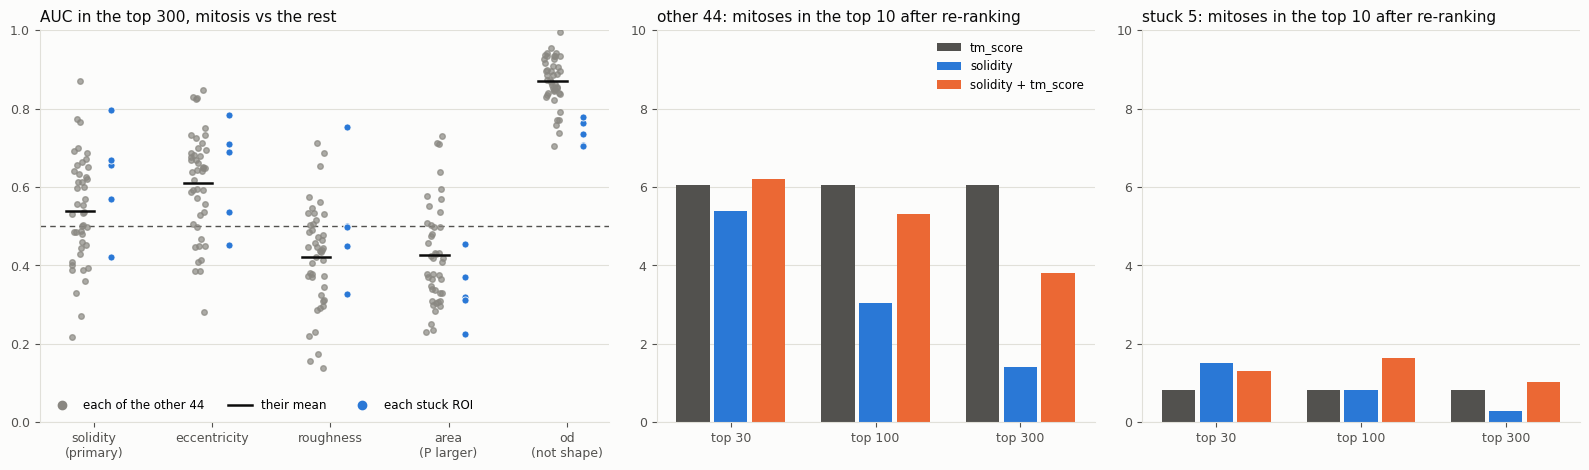

notebook total 12.0 min


In [10]:
# left: per-ROI AUC of each feature at the headline depth; right: mitoses in the top 10 per arm and depth, one panel per group
FEAT_LABEL = {'solidity': 'solidity\n(primary)', 'eccentricity': 'eccentricity', 'roughness': 'roughness', 'area_um2': 'area\n(P larger)', 'od': 'od\n(not shape)'}
ARM_C = {'tm_score': '#52514e', 'solidity': STUCK_C, 'solidity + tm_score': '#eb6834'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor=SURFACE, gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
a = AUC[(AUC['mask'] == 'dil') & (AUC['depth'] == HEAD_DEPTH)]
ax = axes[0]
rng = np.random.default_rng(0)
for k, feat in enumerate(FEATURES):
    o = a[a['group'] == GROUPS[1]][feat].dropna()
    ax.scatter(k - 0.12 + rng.uniform(-0.07, 0.07, len(o)), o, s=16, color=MUTED, alpha=0.7, zorder=2)
    st = a[a['group'] == GROUPS[0]][feat].dropna()
    ax.scatter(np.full(len(st), k + 0.14), st, s=26, color=STUCK_C, zorder=3, edgecolors=SURFACE, linewidths=0.6)
    ax.plot([k - 0.24, k], [o.mean()] * 2, color=INK, linewidth=1.8, zorder=4)
ax.axhline(0.5, color=SECONDARY, linewidth=1.0, linestyle=(0, (4, 3)), zorder=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels([FEAT_LABEL[f] for f in FEATURES], fontsize=8.5)
ax.set_ylim(0, 1)
ax.set_title(f'AUC in the top {HEAD_DEPTH}, mitosis vs the rest', fontsize=11, color=INK, loc='left')
ax.legend(handles=[plt.Line2D([], [], marker='o', linestyle='none', color=MUTED, label='each of the other 44'), plt.Line2D([], [], color=INK, linewidth=1.8, label='their mean'), plt.Line2D([], [], marker='o', linestyle='none', color=STUCK_C, label='each stuck ROI')], fontsize=8.5, frameon=False, loc='lower left', ncol=3)
r = ROI_RR[ROI_RR['mask'] == 'dil'].groupby(['group', 'depth'], sort=False)[[f'tp10 {arm}' for arm in RERANK_ARMS]].mean()
w = 0.26
for ax, grp in zip(axes[1:], GROUPS[::-1]):
    for k, arm in enumerate(RERANK_ARMS):
        ax.bar(np.arange(len(DEPTHS)) + (k - 1) * w, [r.loc[(grp, n), f'tp10 {arm}'] if (grp, n) in r.index else np.nan for n in DEPTHS], width=w - 0.03, color=ARM_C[arm], label=arm, zorder=2)
    ax.set_xticks(range(len(DEPTHS)))
    ax.set_xticklabels([f'top {n}' for n in DEPTHS])
    ax.set_ylim(0, 10)
    ax.set_title(f'{grp}: mitoses in the top 10 after re-ranking', fontsize=11, color=INK, loc='left')
axes[1].legend(fontsize=8.5, frameon=False, loc='upper right')
for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=SECONDARY, labelsize=9)
    ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'):
        ax.spines[sp].set_color(GRID)
fig.tight_layout()
plt.show()
print(f'notebook total {(time.time() - NB_T0) / 60:.1f} min')

## Reading the result

**The gates held.**
- The copied method reproduced the recorded box on all 294 clicks.
- Every list matched the deep-pool run's mitosis counts.
- The stuck five reproduce the first, stuck-five-only run exactly: features, AUCs, re-ranks and refusals.

**Refusals.** 2,067 of 83,773 locations were refused, 1,802 of them at the ROI edge. At the top 300 that drops 2,258 of
88,200 slots, including 139 of 10,574 mitosis slots, all on the other 44. They are dropped from every arm. That moves
the other 44's `tm_score` baseline from 5.94 to 6.04 mitoses in the top 10, and the stuck five's from 0.80 to 0.83.

**Separation is weak, and solidity weakens with depth.** Mean AUC over ROIs, primary mask:

| feature | other 44, top 30 | stuck 5, top 30 | other 44, top 300 | stuck 5, top 300 |
|---|---|---|---|---|
| solidity (primary) | 0.64 | 0.65 | 0.54 | 0.62 |
| eccentricity | 0.59 | 0.57 | 0.61 | 0.63 |
| roughness | 0.56 | 0.65 | 0.42 | 0.51 |
| area (P mitosis larger) | 0.47 | 0.36 | 0.43 | 0.34 |
| od (not shape) | 0.75 | 0.62 | 0.87 | 0.74 |

- On the other 44, solidity points the declared way in 36 of 44 ROIs at the top 30 but only 26 of 44 at the top 300.
  Roughness turns the wrong way at depth.
- Solidity is no weaker in the stuck five than elsewhere. Their problem is not a missing shape signal but how few
  mitoses their lists hold.
- `od` has the highest AUC everywhere (0.87 at the top 300, above 0.5 in all 44 of the other ROIs). But an AUC is not a
  top 10. The recorded `chromatin_od` ranking of the 100-peak pool gets 6.17 mitoses in the top 10 against 5.94 for
  `tm_score` on the other 44, and 0.87 against 0.80 on the stuck five.
- The undilated mask gives the same picture, with solidity a little weaker.

**Re-ranking by solidity.** Mitoses in the top 10, mean over ROIs. The bracket gives the difference from `tm_score`
with its 95% bootstrap interval over ROIs. With 5 ROIs, the stuck five's intervals are rough.

| re-ranked | other 44 `tm_score` | solidity alone | solidity + `tm_score` | stuck 5 `tm_score` | solidity alone | solidity + `tm_score` |
|---|---|---|---|---|---|---|
| top 30 | 6.04 | 5.38 (-0.66 [-1.14, -0.20]) | 6.21 (+0.17 [-0.14, +0.45]) | 0.83 | 1.50 (+0.67 [+0.07, +1.47]) | 1.30 (+0.47 [+0.17, +0.83]) |
| top 100 | 6.04 | 3.04 (-3.00 [-3.68, -2.33]) | 5.32 (-0.72 [-1.24, -0.22]) | 0.83 | 0.83 (0.00 [-0.80, +0.93]) | 1.63 (+0.80 [+0.17, +1.43]) |
| top 300 | 6.04 | 1.41 (-4.63 [-5.25, -4.03]) | 3.80 (-2.24 [-2.94, -1.54]) | 0.83 | 0.30 (-0.53 [-1.03, -0.13]) | 1.03 (+0.20 [-0.20, +0.70]) |

- **On the other 44, solidity never helps.** Alone it loses at every depth. Combined with the score it is flat at the
  top 30 and loses deeper. Going deeper mostly pulls irregular non-mitoses into the top 10. So the higher ceiling of a
  deep pool (P@10 0.90 from the top 100, 0.96 from the top 300, in the deep-pool notebook) is not reachable with
  solidity.
- **On the stuck five, a shallow re-rank adds about half a mitosis per top 10.** With solidity + `tm_score` on the top
  30 or 100, P@10 goes from 8% to 13-16%. The direction holds in the intervals, but it rests on 5 ROIs and stays far
  from useful.
- **The equal-variance model overstates deep re-ranks in both groups.** At the top 300 it predicts 1.90 for solidity
  alone on the other 44, against 1.41 observed; on the stuck five, 0.87 against 0.30.

**What it means.** Chromatin shape, as the adopted segmentation measures it, is a weak signal in both groups. It is not
the lever for precision: it can't lift the stuck five, and it hurts the other 44 once the list is deeper than 30. That
fits the deep-pool notebook. The stuck five need better candidate generation, and the other 44's headroom needs a
stronger re-ranking signal than shape.

**Scope.** Descriptive. The stuck five were picked for their poor top 10, and the bootstrap intervals describe spread
over ROIs; they are not tests. "No label" may include unannotated mitoses, and the visual check of the stuck five is
still open.
